In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline



In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)  

20.0

In [4]:
xs = np.arange(-5, 5, 0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [5]:
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

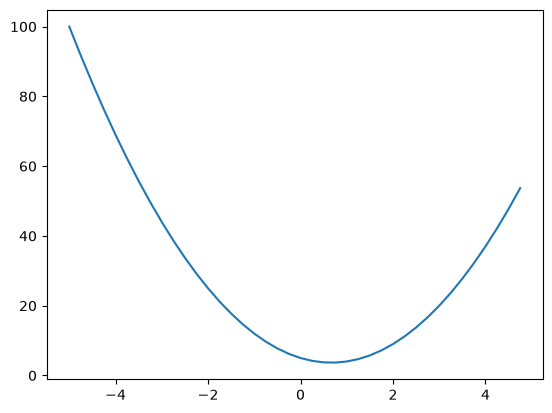

In [6]:
## visualizing the plotting of the function f 
plt.plot(xs, ys)


In [7]:
## visualzing the derivative of f at x is given by the limit as h approaches 0
h = 0.001
x = 3
f(x+h)


20.014003000000002

In [8]:
## the derivative of f at x is given by the limit as h approaches 0
(f(x+h) - f(x))/ (h)

14.00300000000243

In [9]:
# adding complexity 
a = 2
b = -3
c = 10
d = a*b + c
print(d)

4


In [10]:
h = 0.0001
#inputs 
a = 2
b = -3
c = 10
d1 = a*b + c
a += h
d2 = a*b + c
#derivative of d with respect to a 

print('d1', d1)
print('d2',d2)
print('slope', (d2-d1)/h)


d1 4
d2 3.999699999999999
slope -3.000000000010772


In [11]:
h = 0.0001
#inputs : 
a = 2
b = -3
c = 10
d1 = a*b + c
b += h
d2 = a*b + c
#derivative of d with respect to b 

print('d1', d1)
print('d2',d2)
print('slope', (d2-d1)/h)

d1 4
d2 4.0002
slope 2.0000000000042206


In [12]:
h = 0.0001
#inputs : slope = 1 because the slope changes proportionaly to h 
a = 2
b = -3
c = 10
d1 = a*b + c
c += h
d2 = a*b + c
#derivative of d with respect to c 

print('d1', d1)
print('d2',d2)
print('slope', (d2-d1)/h)

d1 4
d2 4.0001
slope 0.9999999999976694


In [13]:

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'** {other}')

        def _backward():
            self.grad += other*(self.data ** (other-1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other): #other * self
        return self*other

    def __radd__(self, other):   # handles  other + self
        return self + other

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (- other)
    
    def tanh(self):                                         # could use relu 
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ),'exp')

        def _backward():
            self.grad = out.data * out.grad
        out._backward = _backward

        return out

    def backward(self): 

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

    # ---------- relu, the other squashing function ----------
    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out

    def __rsub__(self, other):     return (-self) + other      # so 2 - x works
    def __rtruediv__(self, other): return (self**-1) * other    # so 10 / x works

    
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L
d = e + c ; d.label = 'd'
f = Value (-2.0, label='f')
L = d*f ; L.label = 'L'
L


Value(data=-8.0)

In [14]:
a = Value (2.0)
b = Value(4.0)
a - b

Value(data=-2.0)

In [15]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [16]:
d._op

'+'

In [17]:
from graphviz import Digraph
    
def trace(root):   
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges     

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})    
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot


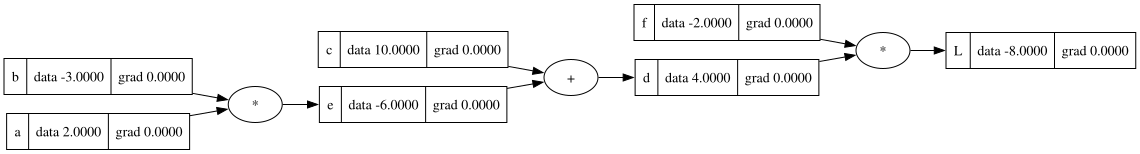

In [18]:
draw_dot(L)

In [19]:
#local variables


def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L.data



    a = Value(2.0, label='a')
    a.data = a.data + h
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()



6.000000000000227


In [20]:
L.grad = 1

In [21]:
f.grad = 4.0
d.grad = -2.0

In [22]:
#dL/dc how is L sensitive to c through d ?
#local derivatives
# c.grad = 1.0
# e.grad = 1.0

#chain rule = product of the local derivatives along the path from L to c
# WANT : 
# dL / dc 

# KNOW :    
# dL / dd = f.grad = -2.0
# dd / dc = c.grad = 1.0

# CHAIN RULE :
# dL / dc = dL / dd * dd / dc = -2.0 * 1.0 = -2.0

In [23]:
c.grad = -2.0
e.grad = -2.0

In [24]:
# dL / da = dL / de * local gradient (de / da) and (de / db)
# local gradients = 
# a.grad = 2
# b.grad = -3

# hence dL / da = -2 * -3 = 6
# hence dL / db = -2 * 2 = -4
a.grad = 6.0
b.grad = -4.0



In [25]:
# test the gradients by doing a gradient descent step and see if the loss decreases
a.data += 0.001 * a.grad
b.data += 0.001 * b.grad
c.data += 0.001 * c.grad
f.data += 0.001 * f.grad

e = a * b 
d = e + c
L = d * f

print(L.data)


-35.955896096


In [26]:
# stopping here for now (3 hours of work) and came back 2 days later for a bit more complex exemple : backprop a neuron 
# explaining the difference between a neuron and backprop 
# introduces tanh (but I dont know why yet, it's a squashing function, to keep the output between -1 and 1, and to introduce non-linearity)
# my first guess it that it stakes whatever the weights are and the input is, and then squashes it to be between -1 and 1, so that the output is not too big or too small, and that it can be used as an input to another neuron.

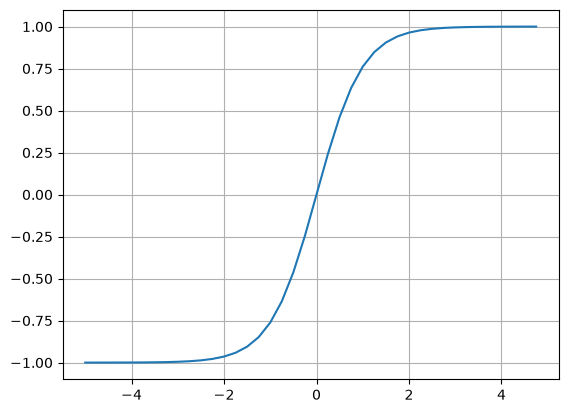

In [27]:
# visualizing the tanh function to see what it looks like
plt.plot(np.arange(-5, 5, 0.25), np.tanh(np.arange(-5, 5, 0.25))); plt.grid()

In [28]:
#inputs x1, x2 (two dimension neuron)
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2 
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# biais 
b = Value(6.8813735870195432, label='b')  # bias changed for a nice number

# x1*w1 + x2*w2 + b but done in steps to visualize the graph
x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

# output, tanh needs to be implemented above first
# draw_dot(o)
# here n is the input to the neuron, and we will apply the tanh activation function to it to get the output of the neuron
# here lets take it through the activation function 


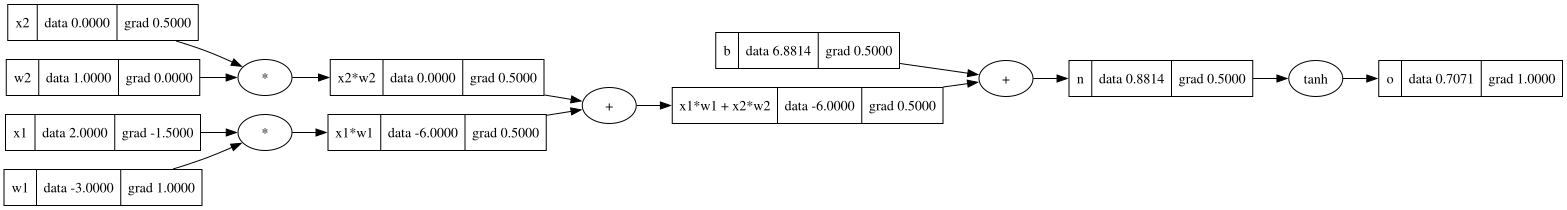

In [29]:
draw_dot(o)

In [30]:
#inputs x1, x2 (two dimension neuron)
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2 
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# biais 
b = Value(6.8813735870195432, label='b')  # bias changed for a nice number

# x1*w1 + x2*w2 + b but done in steps to visualize the graph
x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp()
o = (e - 1) / (e + 1)
o.backward()

# output, tanh needs to be implemented above first
# draw_dot(o)
# here n is the input to the neuron, and we will apply the tanh activation function to it to get the output of the neuron
# here lets take it through the activation function 

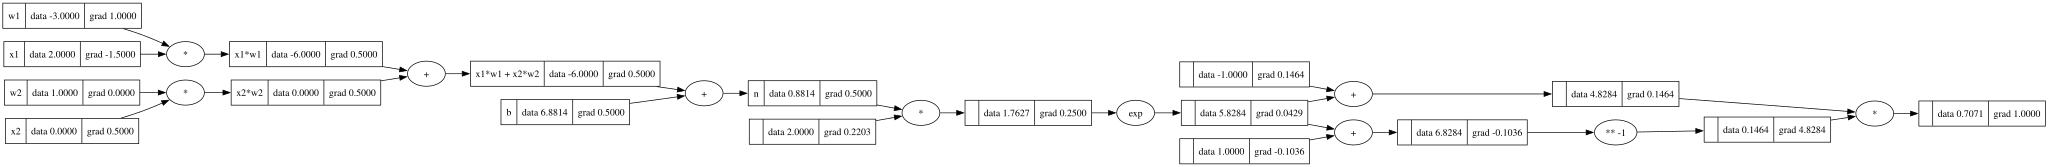

In [31]:
draw_dot(o)

In [32]:
# implementing topological graph 
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo


[Value(data=1),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=6.881373587019543),
 Value(data=0.8813735870195432),
 Value(data=2),
 Value(data=1.7627471740390863),
 Value(data=5.828427124746192),
 Value(data=6.828427124746192),
 Value(data=0.1464466094067262),
 Value(data=-1),
 Value(data=4.828427124746192),
 Value(data=0.7071067811865477)]

In [33]:
# derivative of tanh of o with respect to n is 1 - tanh(n)^2 --> do/dn = 1 - o**2
# print(o.data) (this is the output of the neuron, which is the tanh of n)
# local derivative of o with respect to n is : 
# lets manually backprop through the neuron to see how the gradients flow through the graph
1 - o.data**2
n.grad = 0.5
b.grad = 0.5
x1w1x2w2.grad = 0.5

x1w1.grad = 0.5
x2w2.grad = 0.5

In [34]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

In [35]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [36]:
#w2 doesn't matter for the final output
#w1 goes up then neurons output goes up 
#end of manual propagation manually 

In [37]:
#testing PyTorch
import torch
x1 = torch.Tensor([2.0]).double()                          ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                          ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                         ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                          ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()           ; b.requires_grad = True
n = x1*w1 + x2*w2 + b 
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())



0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [38]:
torch.tensor([2.0]).double().dtype

torch.float64

In [39]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [40]:
import random
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]     #creates the weights, one per input and loops n times, 2 in this case 
        self.b = Value(random.uniform(-1, 1))                           #creates the biais 

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)         #weighted sum 
        out = act.tanh()
        return out         

    def parameters(self):
        return self.w + [self.b]
                    

#what a signle neuron is : weighted sum (w1, w2, wi) of inputs (x1, x2, xi) plus a biais run through a squashing function to stop them between -1 and 1 

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

#a Layer is a set of Neurons (here 3)

class MLP: 
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range (len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters (self):
        return [p for layer in self.layers for p in layer.parameters()]


x = [2.0, 3.0, -1.0]
n = MLP(3,[4,4,1])                                                    
n(x)    


Value(data=0.6622034573329313)

In [41]:
n.parameters()  #41 params

[Value(data=-0.9574727555852394),
 Value(data=-0.21652611490712226),
 Value(data=0.37505461702988474),
 Value(data=0.6756280809960025),
 Value(data=-0.21140186291422225),
 Value(data=0.3155520918713579),
 Value(data=-0.13555906637352844),
 Value(data=-0.30706266918736747),
 Value(data=0.39606968501841355),
 Value(data=0.17798921122620737),
 Value(data=-0.07232956117281297),
 Value(data=-0.5189075880347873),
 Value(data=0.7040841194742582),
 Value(data=-0.5539988761177155),
 Value(data=-0.14185479135194523),
 Value(data=0.7246380126407701),
 Value(data=0.5527658575120096),
 Value(data=0.9956106850558055),
 Value(data=0.0010437410404529057),
 Value(data=0.777971476579097),
 Value(data=-0.14690421841070278),
 Value(data=0.689180804268138),
 Value(data=0.45180856027752325),
 Value(data=-0.6744094286562694),
 Value(data=0.8145741750754874),
 Value(data=-0.15717238436102887),
 Value(data=-0.23056541886851467),
 Value(data=0.2751552177832859),
 Value(data=-0.730507839023752),
 Value(data=-0.5

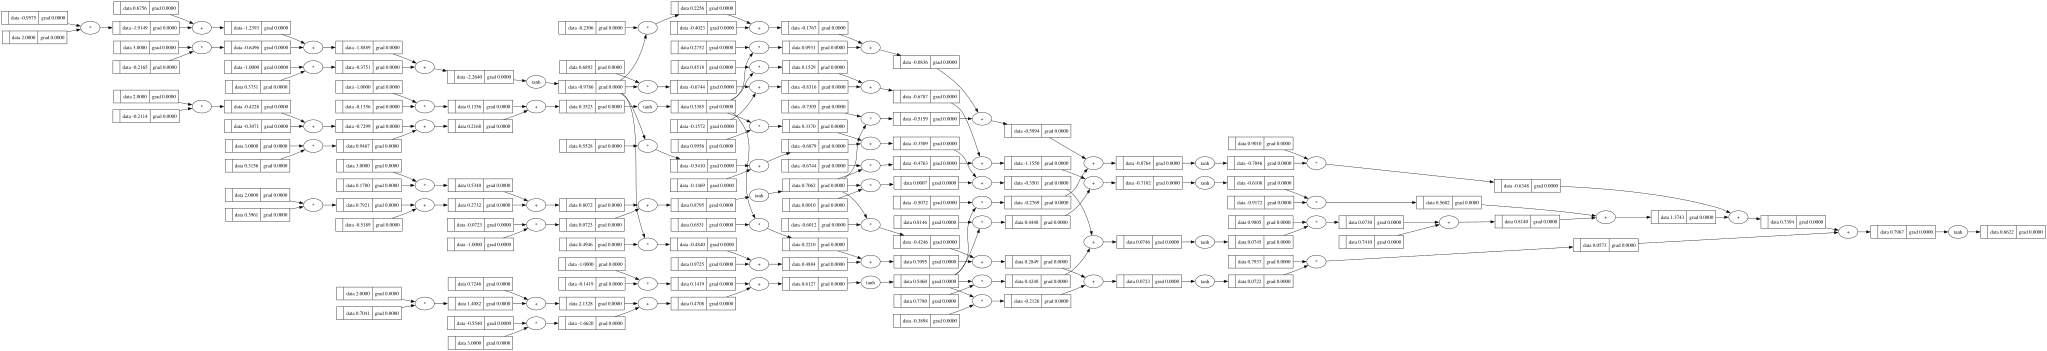

In [42]:
draw_dot(n(x))

In [43]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
    ]

ys = [1.0, -1.0, -1.0, 1.0]                                             #desired ouput
ypred = [n(x) for x in xs]
ypred

[Value(data=0.6622034573329313),
 Value(data=-0.5304734351886821),
 Value(data=0.5417478792856567),
 Value(data=0.42178990458332954)]

In [44]:
# the gradient decent 
for k in range(50):

    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))         #cross entropy loss 

    # backward pass
    for p in n.parameters():
        p.grad = 0.0                                                    #reset to 0 
    loss.backward()

    # update                                                            # could be more sophisticated
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 3.0458751370249164
1 1.4570739879107704
2 0.6680898763031504
3 0.3890372575648572
4 0.2000062342837504
5 0.15461828565957578
6 0.12490076150726029
7 0.10409317602035864
8 0.08880186311453563
9 0.07714274855459739
10 0.0679914885637126
11 0.060638379386484156
12 0.054614824644339824
13 0.04959978596568127
14 0.045366424054103766
15 0.04175020563333532
16 0.03862907304801044
17 0.03591069049287316
18 0.03352399804610775
19 0.03141347353258189
20 0.029535145075742758
21 0.02785376404618435
22 0.02634076439658107
23 0.024972765627137346
24 0.023730458367769446
25 0.022597763669719766
26 0.02156119102214392
27 0.020609342621469712
28 0.019732526625158713
29 0.018922452555843232
30 0.018171989289598362
31 0.017474971193963566
32 0.01682604165116658
33 0.016220525857412064
34 0.015654326731674405
35 0.015123839203173055
36 0.014625879218072887
37 0.014157624612645938
38 0.01371656561269493
39 0.013300463187918915
40 0.012907313851501227
41 0.012535319776060358
42 0.0121828633167234
43 0.011

In [45]:
ypred

[Value(data=0.9867947236799677),
 Value(data=-0.9446302307649276),
 Value(data=-0.9404518861235536),
 Value(data=0.9419508401040774)]

In [46]:
n.layers[0].neurons[0].w[0]

Value(data=-0.9724808916642447)

In [47]:
n.layers[0].neurons[0].w[0].grad

0.0018251939946084378

In [48]:
n.parameters()

[Value(data=-0.9724808916642447),
 Value(data=-0.2364612440758045),
 Value(data=0.4569447524047732),
 Value(data=0.6658311825643722),
 Value(data=-0.10852069828515258),
 Value(data=0.3975705598817116),
 Value(data=-0.8467435445958443),
 Value(data=-0.3674653677301449),
 Value(data=0.3247862691894706),
 Value(data=0.1770443395593077),
 Value(data=0.0027316865511685545),
 Value(data=-0.5319850101804592),
 Value(data=0.6457696193698087),
 Value(data=-0.5688717677918387),
 Value(data=0.07987001694892226),
 Value(data=0.7360925131011714),
 Value(data=0.3149777450036565),
 Value(data=1.3141600142918182),
 Value(data=0.07405509358900056),
 Value(data=0.7162718565121741),
 Value(data=-0.3299787128006039),
 Value(data=0.8679206774495976),
 Value(data=0.1225501757464474),
 Value(data=-0.7115098498873604),
 Value(data=0.8762425724632468),
 Value(data=-0.015511539170724637),
 Value(data=-0.4219857680640251),
 Value(data=0.492393358676883),
 Value(data=-0.6826372211996011),
 Value(data=-0.496198596

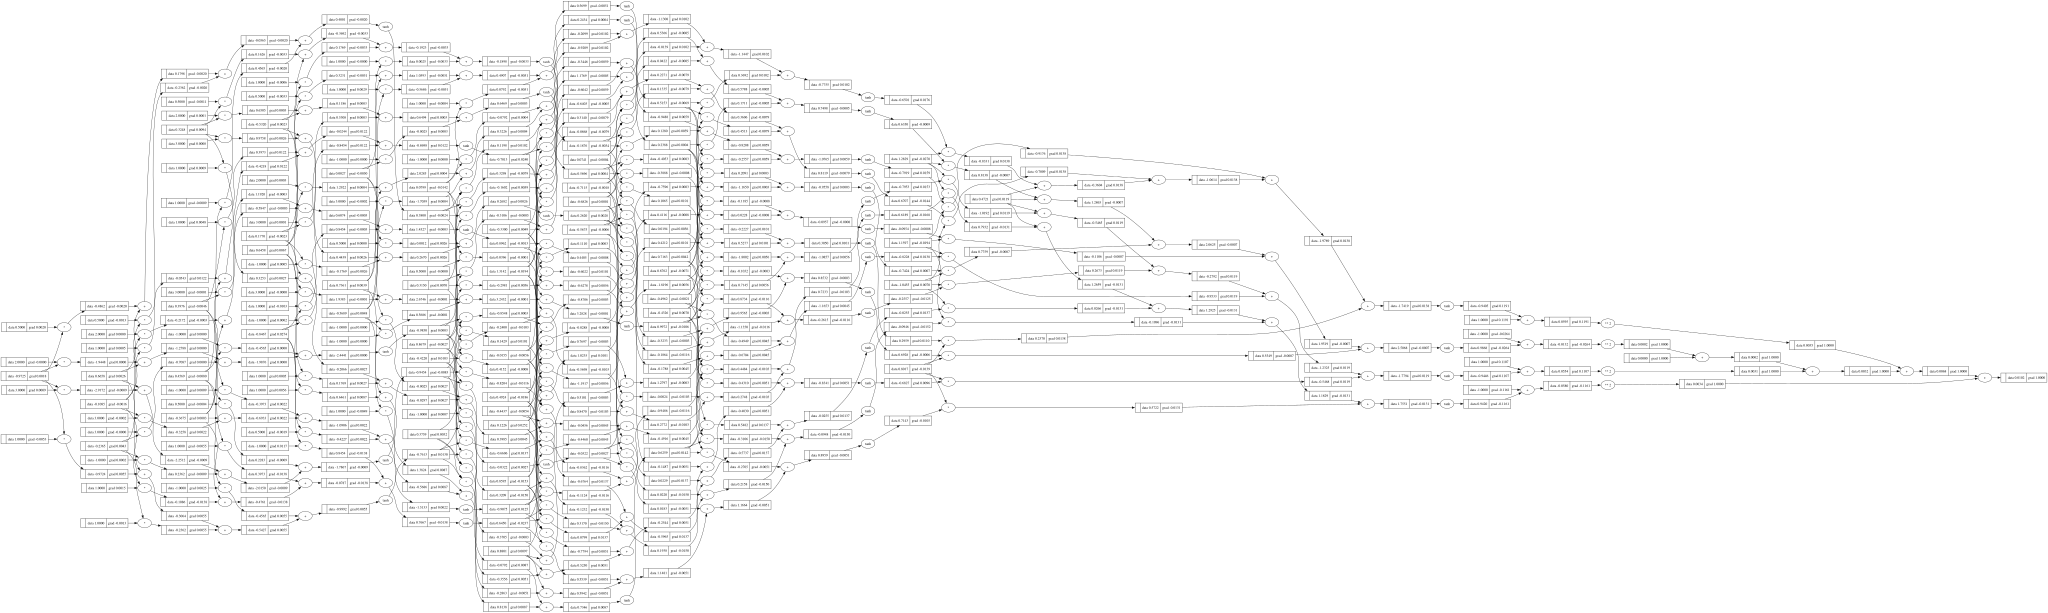

In [49]:
draw_dot(loss)      #huge graph 